In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer

In [2]:
df = pd.read_csv('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn-2.csv')

In [3]:
print(df.shape)
print()
print(df.head())
print()
print(df.info())
print()
print(df.describe(include='all'))

(7043, 21)

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        C

In [4]:
df.groupby('Churn')['tenure'].agg(['mean', 'median', 'min', 'max'])

,mean,median,min,max
Churn,,,,
No,37.569965,38.0,0,72
Yes,17.979133,10.0,1,72


In [5]:
df.groupby('Churn')['MonthlyCharges'].agg(['mean', 'median', 'min', 'max'])

,mean,median,min,max
Churn,,,,
No,61.265124,64.425,18.25,118.75
Yes,74.441332,79.650,18.85,118.35


In [6]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.groupby('Churn')['TotalCharges'].agg(['mean', 'median', 'min', 'max'])

,mean,median,min,max
Churn,,,,
No,2555.344141,1683.60,18.80,8672.45
Yes,1531.796094,703.55,18.85,8684.80


<Axes: xlabel='Churn', ylabel='TotalCharges'>

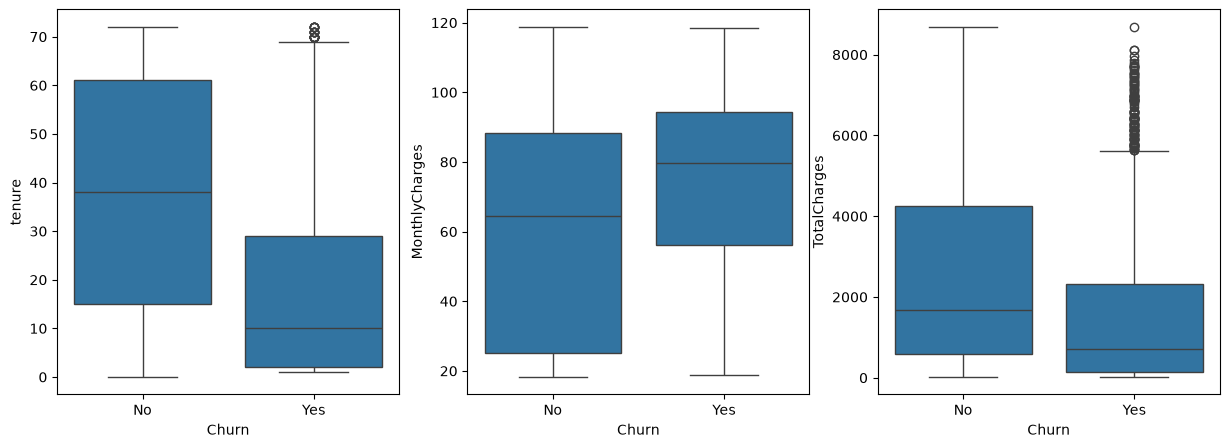

In [7]:
fig , axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(x='Churn', y='tenure', data=df, ax=axes[0])
sns.boxplot(x='Churn', y='MonthlyCharges', data=df, ax=axes[1])
sns.boxplot(x='Churn', y='TotalCharges', data=df, ax=axes[2])

In [11]:
pd.crosstab(df['Contract'],df['Churn'],normalize='index')*100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


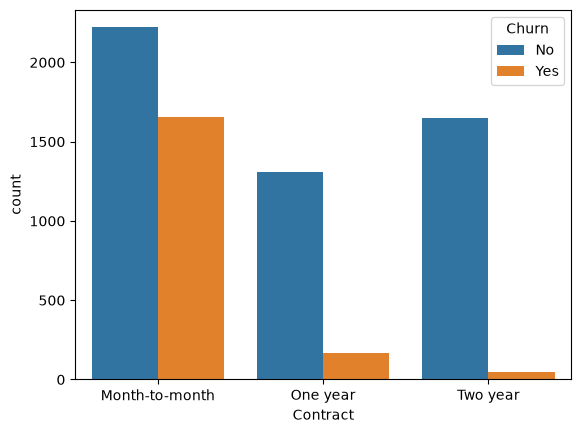

In [15]:
sns.countplot(data=df , x='Contract' , hue='Churn')
plt.show()

In [16]:
df.groupby('Churn')['tenure'].agg(['mean', 'median', 'min', 'max'])

,mean,median,min,max
Churn,,,,
No,37.569965,38.0,0,72
Yes,17.979133,10.0,1,72


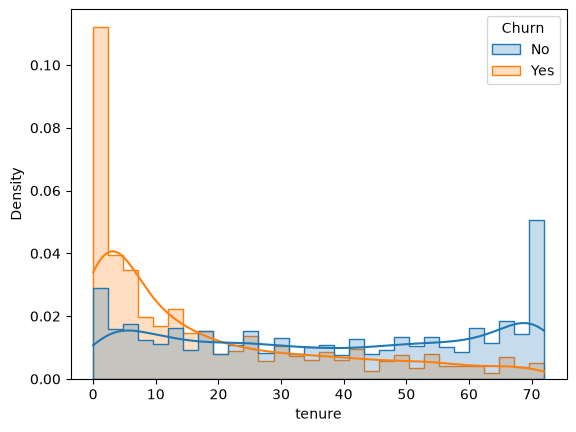

In [24]:
sns.histplot(data=df , x='tenure' , hue='Churn' , bins=30 , kde=True , element='step' , stat='density' , common_norm=False)
plt.show()

In [44]:
pd.crosstab(df['PaymentMethod'],df['Churn'],normalize='index')*100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


<Axes: xlabel='PaymentMethod', ylabel='count'>

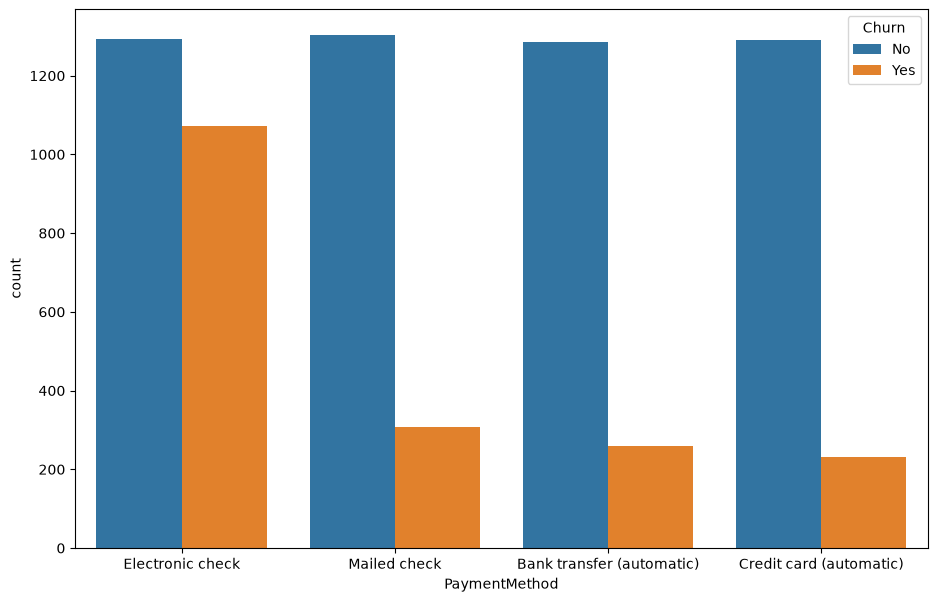

In [30]:
plt.figure(figsize=(11,7))
sns.countplot(data = df , x='PaymentMethod' , hue='Churn')

In [34]:
df.groupby('Churn')['MonthlyCharges'].agg(['mean' , 'min' , 'max'])

,mean,min,max
Churn,,,
No,61.265124,18.25,118.75
Yes,74.441332,18.85,118.35


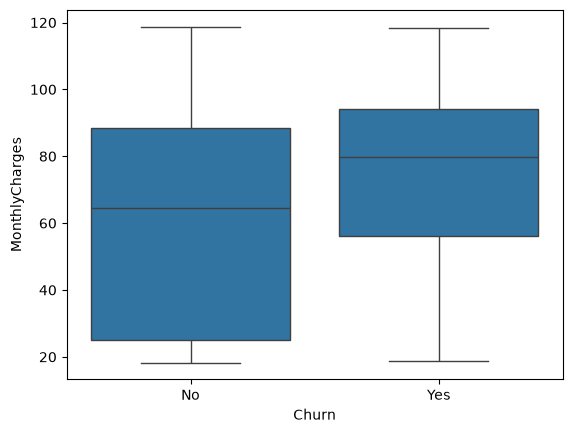

In [43]:
sns.boxplot(data=df , x="Churn" , y="MonthlyCharges")
plt.show()

In [45]:
df['ChargeGroup'] = pd.cut(
    df['MonthlyCharges'],
    bins=4
)
pd.crosstab(
    df['ChargeGroup'],
    df['Churn'],
    normalize='index'
)*100

Churn,No,Yes
ChargeGroup,,
"(18.15, 43.375]",87.677725,12.322275
"(43.375, 68.5]",78.503994,21.496006
"(68.5, 93.625]",63.187773,36.812227
"(93.625, 118.75]",66.418416,33.581584


In [46]:
pd.crosstab(
    df['PaymentMethod'],
    df['Contract'],
    normalize='index'
)*100

Contract,Month-to-month,One year,Two year
PaymentMethod,,,
Bank transfer (automatic),38.147668,25.323834,36.528497
Credit card (automatic),35.676741,26.149803,38.173456
Electronic check,78.224101,14.672304,7.103594
Mailed check,55.397022,20.905707,23.697270


In [48]:
churn_analysis = pd.crosstab(
    index= [df["PaymentMethod"], df["Contract"]],
    columns=df["Churn"],
    normalize='index'
)*100
churn_analysis.round(2)

Churn                                        No    Yes
PaymentMethod             Contract                    
Bank transfer (automatic) Month-to-month  65.87  34.13
                          One year        90.28   9.72
                          Two year        96.63   3.37
Credit card (automatic)   Month-to-month  67.22  32.78
                          One year        89.70  10.30
                          Two year        97.76   2.24
Electronic check          Month-to-month  46.27  53.73
                          One year        81.56  18.44
                          Two year        92.26   7.74
Mailed check              Month-to-month  68.42  31.58
                          One year        93.18   6.82
                          Two year        99.21   0.79

In [50]:
customer_counts = pd.crosstab(
    index = [df["PaymentMethod"], df["Contract"]],
    columns = df["Churn"]
)
customer_counts

Churn                                      No  Yes
PaymentMethod             Contract                
Bank transfer (automatic) Month-to-month  388  201
                          One year        353   38
                          Two year        545   19
Credit card (automatic)   Month-to-month  365  178
                          One year        357   41
                          Two year        568   13
Electronic check          Month-to-month  856  994
                          One year        283   64
                          Two year        155   13
Mailed check              Month-to-month  611  282
                          One year        314   23
                          Two year        379    3

In [51]:
pd.crosstab(
    index=[df["Contract"],df["PaymentMethod"]],
    columns=df["Churn"]
)

Churn                                      No  Yes
Contract       PaymentMethod                      
Month-to-month Bank transfer (automatic)  388  201
               Credit card (automatic)    365  178
               Electronic check           856  994
               Mailed check               611  282
One year       Bank transfer (automatic)  353   38
               Credit card (automatic)    357   41
               Electronic check           283   64
               Mailed check               314   23
Two year       Bank transfer (automatic)  545   19
               Credit card (automatic)    568   13
               Electronic check           155   13
               Mailed check               379    3

In [53]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
ChargeGroup          0
dtype: int64

In [54]:
df.dtypes

customerID               str
gender                   str
SeniorCitizen          int64
Partner                  str
Dependents               str
tenure                 int64
PhoneService             str
MultipleLines            str
InternetService          str
OnlineSecurity           str
OnlineBackup             str
DeviceProtection         str
TechSupport              str
StreamingTV              str
StreamingMovies          str
Contract                 str
PaperlessBilling         str
PaymentMethod            str
MonthlyCharges       float64
TotalCharges         float64
Churn                    str
ChargeGroup         category
dtype: object

In [56]:
df.duplicated().sum()

np.int64(0)

In [57]:
df[df["TotalCharges"].isna()][["tenure" , "MonthlyCharges" , "TotalCharges"]]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [58]:
df['TotalCharges']=df['TotalCharges'].fillna(0)

In [59]:
df['TotalCharges'].isnull().sum()

np.int64(0)

In [60]:
X = df.drop(columns=["Churn","customerID"])
y = df["Churn"]

print(X.shape)
print(y.shape)
print(X.columns)

(7043, 20)
(7043,)
Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'ChargeGroup'],
      dtype='str')


In [65]:
categorical_features = X.select_dtypes(include=["object","str"]).columns
print(categorical_features)
print(len(categorical_features))

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='str')
15


In [68]:
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

In [69]:
x_train , x_test , y_train , y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(5634, 20)
(1409, 20)
(5634,)
(1409,)


In [70]:
numercial_features = X.select_dtypes(
    include=["int64" , "float64"]
).columns

In [71]:
numercial_features

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')

In [76]:
preprocessor = ColumnTransformer(
    transformers = [
        ("cat", encoder, categorical_features),
        ("num", "passthrough", numercial_features)
    ]
)

In [77]:
x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed = preprocessor.transform(x_test)

In [79]:
print(x_train_processed.shape)
print(x_test_processed.shape)
print(type(x_train_processed))

(5634, 45)
(1409, 45)
<class 'numpy.ndarray'>
